#  Résultat de la recherche d'exoplanet de Kepler

**Pipeline suivi : `Data → EDA → Prétraitement → ML → EVAL → Deploy`**

Ce notebook reprend l'analyse visuelle d'origine et la complète pour couvrir les étapes d'un projet de data science.

---
# 1 DATA - Collecte et audit de la qualité

**Objectif de l'étape** : charger les données, vérifier leur structure et mesurer leur qualité avant toute analyse.



In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.impute import SimpleImputer
data_file =r"cumulative.csv"
df = pd.read_csv(data_file) 

---
# 1bis DATA - Dictionnaire des données

Le fichier `cumulative.csv` provient de l'archive NASA Exoplanet Archive (table *Kepler Objects of Interest*) : **9 564 lignes × 50 colonnes**, une ligne par signal candidat (KOI).

**Convention d'erreurs** : pour chaque mesure `X`, `X_err1` est l'incertitude **haute** (positive) et `X_err2` l'incertitude **basse** (négative).

### Identification

| Colonne | Signification | Unité / valeurs |
|---|---|---|
| `rowid` | Numéro de ligne dans l'archive | 1 à 9564 |
| `kepid` | Identifiant de l'étoile hôte (catalogue Kepler Input Catalog). Une étoile peut avoir plusieurs KOI | entier ; 8214 étoiles uniques |
| `kepoi_name` | Nom du KOI (Kepler Object of Interest) : `K00752.01` = système KOI n°752, signal n°1 | texte |
| `kepler_name` | Nom officiel `Kepler-227 b`, attribué seulement aux planètes confirmées | texte ; ~76 % vides |

### Classification (cibles et verdicts du pipeline)

| Colonne | Signification | Unité / valeurs |
|---|---|---|
| `koi_disposition` | Statut final dans l'archive NASA : **variable cible** du notebook | CONFIRMED / CANDIDATE / FALSE POSITIVE |
| `koi_pdisposition` | Statut selon les seules données Kepler (avant confirmation externe) | CANDIDATE / FALSE POSITIVE |
| `koi_score` | Score de confiance du pipeline que le signal est un vrai candidat (⚠ dérivé du verdict : risque de fuite) | 0 à 1 |
| `koi_fpflag_nt` | Drapeau *Not Transit-like* : le signal ne ressemble pas à un transit (bruit, instrument, variabilité) | 0 / 1 |
| `koi_fpflag_ss` | Drapeau *Stellar Eclipse* : éclipse secondaire significative → binaire à éclipses | 0 / 1 |
| `koi_fpflag_co` | Drapeau *Centroid Offset* : le signal vient d'une étoile voisine, pas de la cible | 0 / 1 |
| `koi_fpflag_ec` | Drapeau *Ephemeris Match* : même période/époque qu'un autre objet connu → contamination | 0 / 1 |

### Signal de transit et orbite

| Colonne | Signification | Unité / valeurs |
|---|---|---|
| `koi_period` (+ `_err1`, `_err2`) | Période orbitale | jours |
| `koi_time0bk` (+ `_err1`, `_err2`) | Date du premier transit observé | BKJD = BJD − 2 454 833,0 (jours) |
| `koi_impact` (+ `_err1`, `_err2`) | Paramètre d'impact : distance entre le centre du disque stellaire et la trajectoire du transit (0 = central, >1 = rasant) | en rayons stellaires |
| `koi_duration` (+ `_err1`, `_err2`) | Durée du transit | heures |
| `koi_depth` (+ `_err1`, `_err2`) | Profondeur du transit : baisse de luminosité de l'étoile | ppm |
| `koi_model_snr` | Rapport signal/bruit du transit ajusté | sans unité |
| `koi_tce_plnt_num` | Rang du signal détecté (Threshold Crossing Event) autour de l'étoile | 1 à 8 |
| `koi_tce_delivname` | Version du pipeline de détection (livraison de données Kepler) | q1_q17_dr25_tce / q1_q16_tce / q1_q17_dr24_tce |

### Propriétés de la planète

| Colonne | Signification | Unité / valeurs |
|---|---|---|
| `koi_prad` (+ `_err1`, `_err2`) | Rayon estimé de la planète | rayons terrestres |
| `koi_teq` (+ `_err1`, `_err2`) | Température d'équilibre estimée (à partir de l'étoile et de l'orbite). Les colonnes d'erreur sont 100 % vides | kelvins |
| `koi_insol` (+ `_err1`, `_err2`) | Flux d'insolation reçu par la planète | relatif à la Terre (Terre = 1) |

### Propriétés de l'étoile hôte

| Colonne | Signification | Unité / valeurs |
|---|---|---|
| `koi_steff` (+ `_err1`, `_err2`) | Température effective de l'étoile | kelvins |
| `koi_slogg` (+ `_err1`, `_err2`) | Gravité de surface de l'étoile | log10(cm/s²) |
| `koi_srad` (+ `_err1`, `_err2`) | Rayon de l'étoile | rayons solaires |
| `ra` | Ascension droite (position céleste) | degrés |
| `dec` | Déclinaison (position céleste) | degrés |
| `koi_kepmag` | Magnitude apparente dans la bande Kepler (plus petit = plus brillant) | mag |

### Points de vigilance
- **Fuite de données (data leakage)** : `koi_score`, `koi_pdisposition` et les 4 `koi_fpflag_*` sont produits par le processus de vérification qui décide du statut. Les utiliser pour prédire `koi_disposition` donne un score artificiellement élevé ; ils sont exclus du modèle PySpark plus bas.
- **Valeurs manquantes** : `koi_teq_err1/err2` sont vides à 100 % ; `koi_score` manque 1 510 fois ; la plupart des mesures physiques manquent ~363 fois.
- **Distributions très asymétriques** (`koi_prad` jusqu'à 200 000, `koi_depth`, `koi_insol`, `koi_model_snr`) : une transformation `log1p` est pertinente.
- **Classes déséquilibrées** : FALSE POSITIVE 5 023, CONFIRMED 2 293, CANDIDATE 2 248.


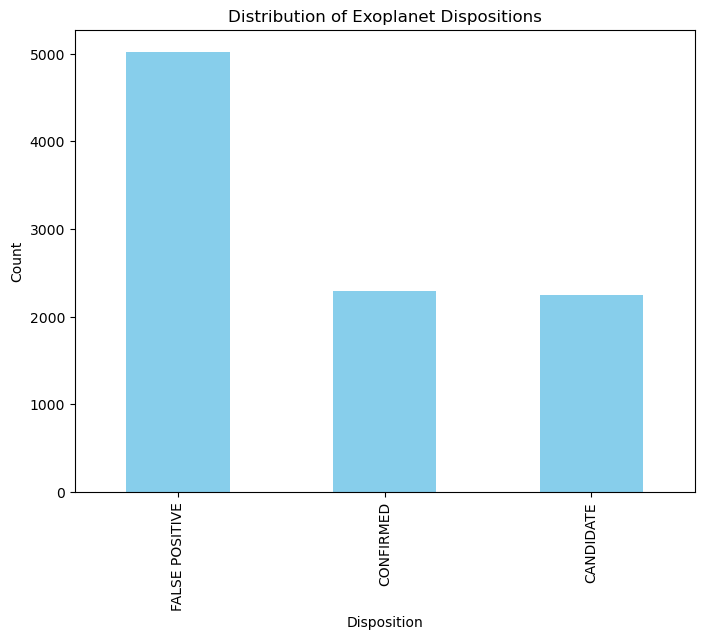

In [2]:
def explore_disposition_distribution(data):
    plt.figure(figsize=(8, 6))
    disposition_counts = data['koi_disposition'].value_counts()
    disposition_counts.plot(kind='bar', color='skyblue')
    plt.title('Distribution of Exoplanet Dispositions')
    plt.xlabel('Disposition')
    plt.ylabel('Count')
    plt.show()
explore_disposition_distribution(df)

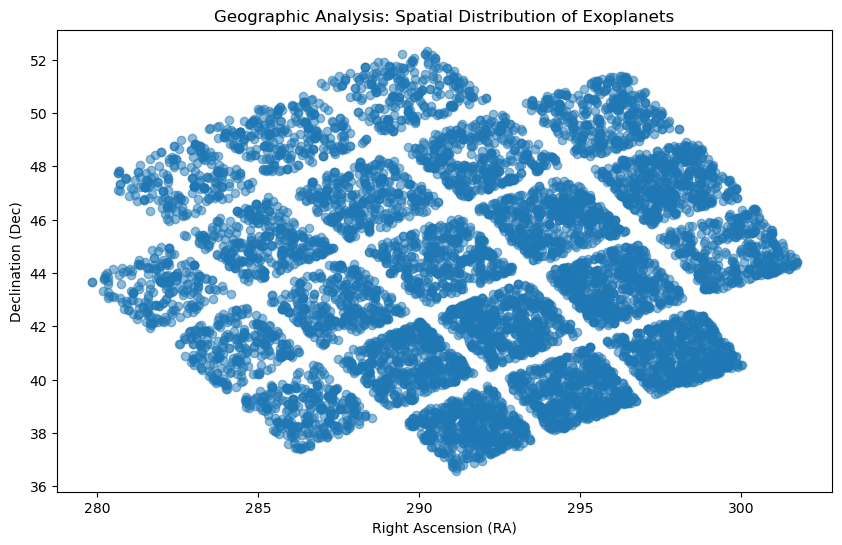

In [3]:
def geographic_analysis(data, ra_column, dec_column):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')
    data[[ra_column, dec_column]] = imputer.fit_transform(data[[ra_column, dec_column]])

    # Plot the spatial distribution
    plt.figure(figsize=(10, 6))
    plt.scatter(data[ra_column], data[dec_column], alpha=0.5)
    plt.title('Geographic Analysis: Spatial Distribution of Exoplanets')
    plt.xlabel('Right Ascension (RA)')
    plt.ylabel('Declination (Dec)')
    plt.show()

# Example usage for geographic analysis
geographic_analysis(df, 'ra', 'dec')


In [4]:
def statistical_summary_analysis(data, columns_to_include):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')
    data[columns_to_include] = imputer.fit_transform(data[columns_to_include])

    # Generate statistical summary
    summary = data[columns_to_include].describe()

    return summary

# Example usage for statistical summary analysis
columns_to_include_summary = ['koi_period', 'koi_duration', 'koi_prad', 'koi_teq']
summary_result = statistical_summary_analysis(df, columns_to_include_summary)

# Display the summary
print(summary_result)


          koi_period  koi_duration       koi_prad       koi_teq
count    9564.000000   9564.000000    9564.000000   9564.000000
mean       75.671358      5.621606     102.891778   1085.385828
std      1334.744046      6.471554    3018.662296    839.940895
min         0.241843      0.052000       0.080000     25.000000
25%         2.733684      2.437750       1.430000    553.000000
50%         9.752831      3.792600       2.490000    906.000000
75%        40.715178      6.276500      21.712500   1352.500000
max    129995.778400    138.540000  200346.000000  14667.000000


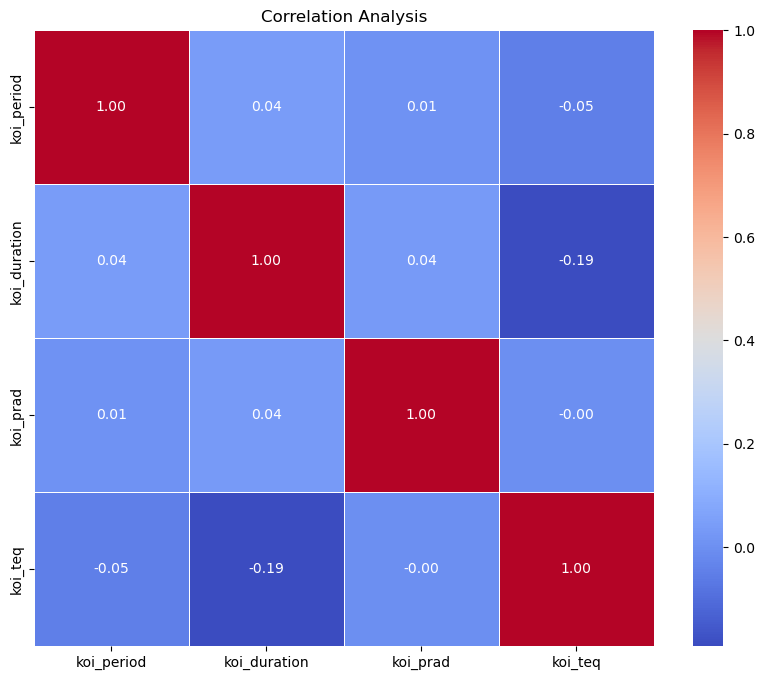

In [5]:
import seaborn as sns

def correlation_analysis(data, columns_to_include):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')
    data[columns_to_include] = imputer.fit_transform(data[columns_to_include])

    # Compute the correlation matrix
    correlation_matrix = data[columns_to_include].corr()

    # Plot the heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Correlation Analysis')
    plt.show()

# Example usage for correlation analysis
columns_to_include_correlation = ['koi_period', 'koi_duration', 'koi_prad', 'koi_teq']
correlation_analysis(df, columns_to_include_correlation)


C:\Users\johan\AppData\Local\Temp\ipykernel_25452\3387215731.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')


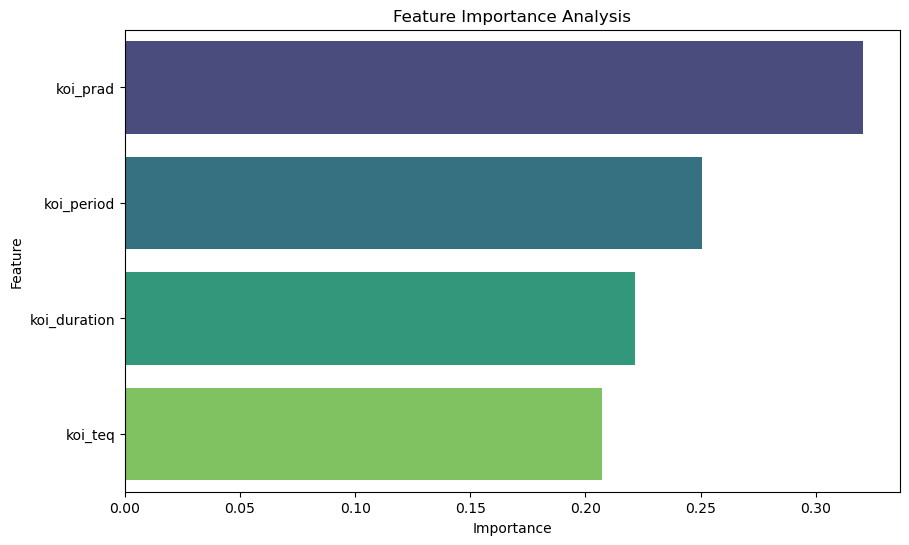

In [6]:
def feature_importance_analysis(data, target_column, features_columns):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')
    data[features_columns] = imputer.fit_transform(data[features_columns])

    # Split the data into features (X) and target variable (y)
    X = data[features_columns]
    y = data[target_column]

    # Initialize a RandomForestClassifier (you can choose a different classifier)
    clf = RandomForestClassifier(n_estimators=100, random_state=42)

    # Train the model
    clf.fit(X, y)

    # Extract feature importances
    feature_importances = clf.feature_importances_

    # Create a DataFrame for better visualization
    importance_df = pd.DataFrame({'Feature': features_columns, 'Importance': feature_importances})
    importance_df = importance_df.sort_values(by='Importance', ascending=False)

    # Plot the feature importances
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
    plt.title('Feature Importance Analysis')
    plt.show()

# Example usage for feature importance analysis
target_column_importance = 'koi_disposition'
features_columns_importance = ['koi_period', 'koi_duration', 'koi_prad', 'koi_teq']
feature_importance_analysis(df, target_column_importance, features_columns_importance)


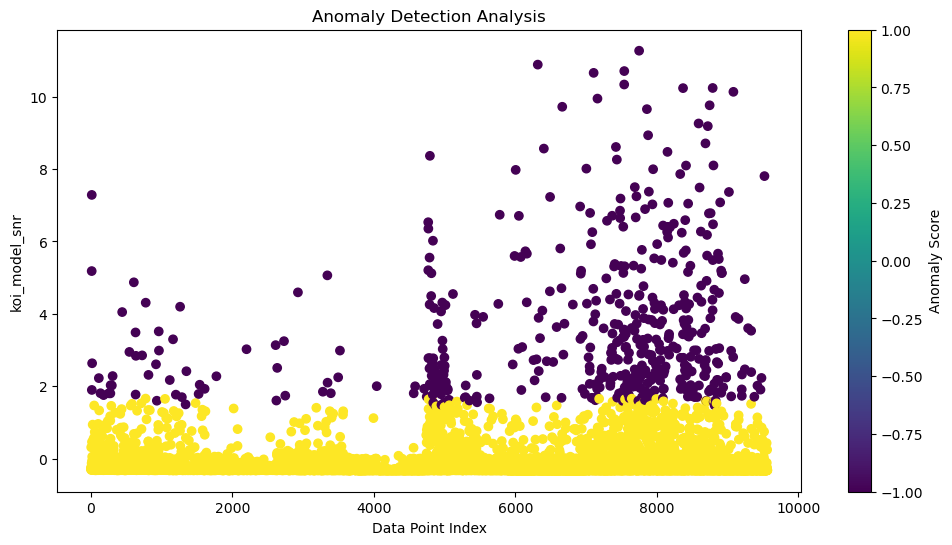

In [7]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

def anomaly_detection_analysis(data, anomaly_feature):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')
    data[[anomaly_feature]] = imputer.fit_transform(data[[anomaly_feature]])

    # Standardize the anomaly feature
    scaler = StandardScaler()
    data[anomaly_feature] = scaler.fit_transform(data[[anomaly_feature]])

    # Apply Isolation Forest
    iso_forest = IsolationForest(contamination=0.05, random_state=42)  # Adjust contamination parameter
    data['anomaly_score'] = iso_forest.fit_predict(data[[anomaly_feature]])

    # Visualize anomalies
    plt.figure(figsize=(12, 6))
    plt.scatter(data.index, data[anomaly_feature], c=data['anomaly_score'], cmap='viridis')
    plt.title('Anomaly Detection Analysis')
    plt.xlabel('Data Point Index')
    plt.ylabel(anomaly_feature)
    plt.colorbar(label='Anomaly Score')
    plt.show()

# Example usage for anomaly detection analysis
anomaly_feature = 'koi_model_snr'
anomaly_detection_analysis(df, anomaly_feature)


In [8]:
def classification_analysis(data, target_column, features_columns):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')  # You can choose a different strategy if needed
    data[features_columns] = imputer.fit_transform(data[features_columns])

    # Split the data into features (X) and target variable (y)
    X = data[features_columns]
    y = data[target_column]

    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Initialize a RandomForestClassifier (you can choose a different classifier)
    clf = RandomForestClassifier(n_estimators=100, random_state=42)

    # Train the model
    clf.fit(X_train, y_train)

    # Make predictions
    y_pred = clf.predict(X_test)

    # Evaluate the model
    accuracy = accuracy_score(y_test, y_pred)
    confusion_mat = confusion_matrix(y_test, y_pred)
    classification_rep = classification_report(y_test, y_pred)

    print(f'Accuracy: {accuracy:.2f}')
    print('\nConfusion Matrix:')
    print(confusion_mat)
    print('\nClassification Report:')
    print(classification_rep)


In [9]:
target_column = 'koi_disposition'
features_columns = ['koi_period', 'koi_duration', 'koi_prad', 'koi_teq']  # Replace with relevant features

# Perform classification analysis
classification_analysis(df, target_column, features_columns)

Accuracy: 0.71

Confusion Matrix:
[[178 125 148]
 [ 92 333  29]
 [101  64 843]]

Classification Report:
                precision    recall  f1-score   support

     CANDIDATE       0.48      0.39      0.43       451
     CONFIRMED       0.64      0.73      0.68       454
FALSE POSITIVE       0.83      0.84      0.83      1008

      accuracy                           0.71      1913
     macro avg       0.65      0.65      0.65      1913
  weighted avg       0.70      0.71      0.70      1913



In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

def regression_analysis(data, target_column, features_columns):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')
    data[features_columns] = imputer.fit_transform(data[features_columns])

    # Split the data into features (X) and target variable (y)
    X = data[features_columns]
    y = data[target_column]

    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Initialize a Linear Regression model (you can choose a different regressor)
    regressor = LinearRegression()

    # Train the model
    regressor.fit(X_train, y_train)

    # Make predictions
    y_pred = regressor.predict(X_test)

    # Evaluate the model
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f'Mean Squared Error: {mse:.2f}')
    print(f'R-squared: {r2:.2f}')

# Define target column and features for regression
target_column_regression = 'koi_prad'
features_columns_regression = ['koi_period', 'koi_duration', 'koi_teq']  # Replace with relevant features

# Perform regression analysis with missing value handling
regression_analysis(df, target_column_regression, features_columns_regression)

Mean Squared Error: 458582.95
R-squared: -0.06


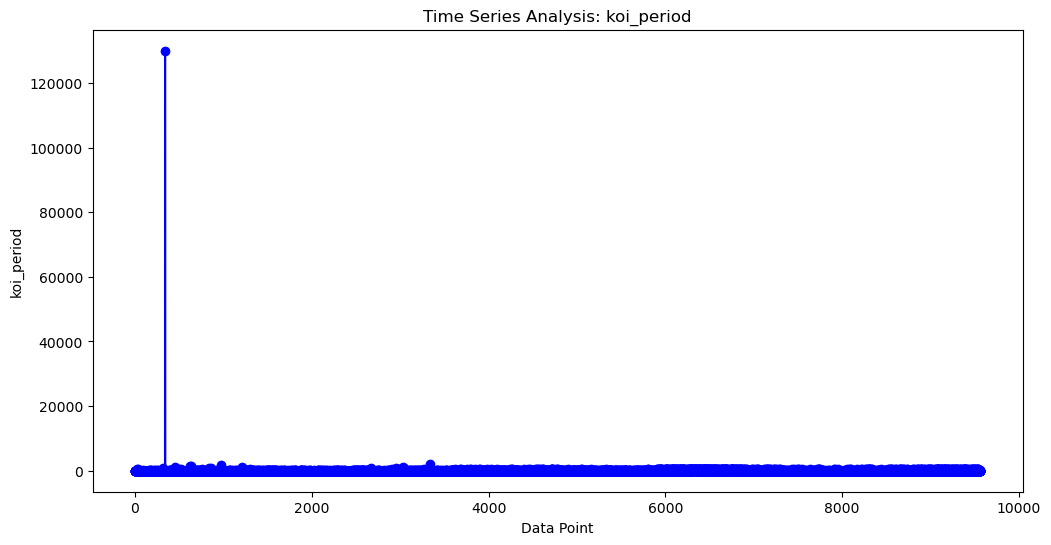

Autocorrelation of koi_period: 0.00


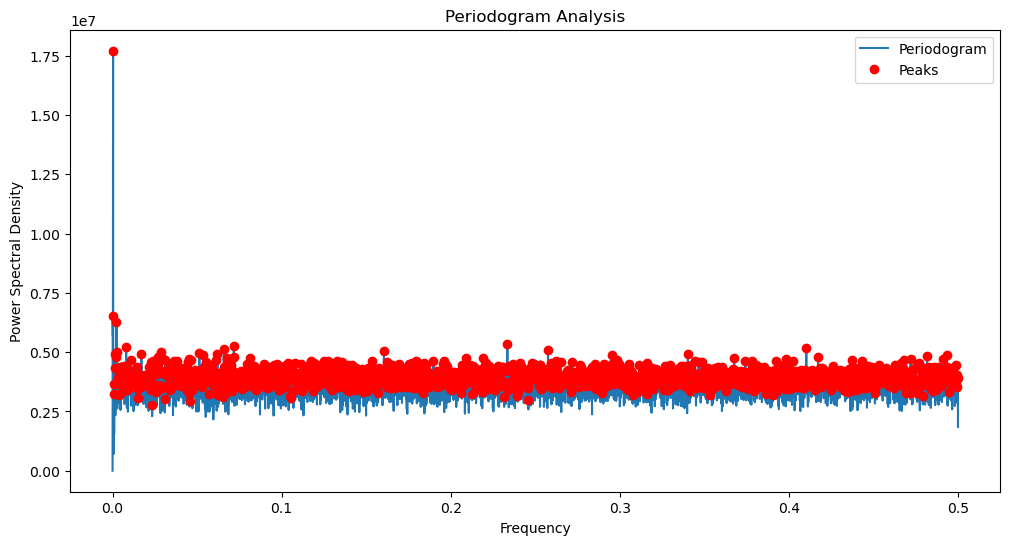

In [11]:
from scipy.signal import periodogram, find_peaks

def time_series_analysis(data, period_feature):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')
    data[period_feature] = imputer.fit_transform(data[[period_feature]])

    # Plot the time series
    plt.figure(figsize=(12, 6))
    plt.plot(data[period_feature], marker='o', linestyle='-', color='b')
    plt.title(f'Time Series Analysis: {period_feature}')
    plt.xlabel('Data Point')
    plt.ylabel(period_feature)
    plt.show()

    # Autocorrelation analysis
    autocorrelation = data[period_feature].autocorr()
    print(f'Autocorrelation of {period_feature}: {autocorrelation:.2f}')

    # Periodogram analysis
    f, Pxx = periodogram(data[period_feature])
    peaks, _ = find_peaks(Pxx, height=0.02)  # Adjust height parameter based on your data
    plt.figure(figsize=(12, 6))
    plt.plot(f, Pxx, label='Periodogram')
    plt.plot(f[peaks], Pxx[peaks], 'ro', label='Peaks')
    plt.title('Periodogram Analysis')
    plt.xlabel('Frequency')
    plt.ylabel('Power Spectral Density')
    plt.legend()
    plt.show()

# Example usage for time series analysis
time_series_analysis(df, 'koi_period')

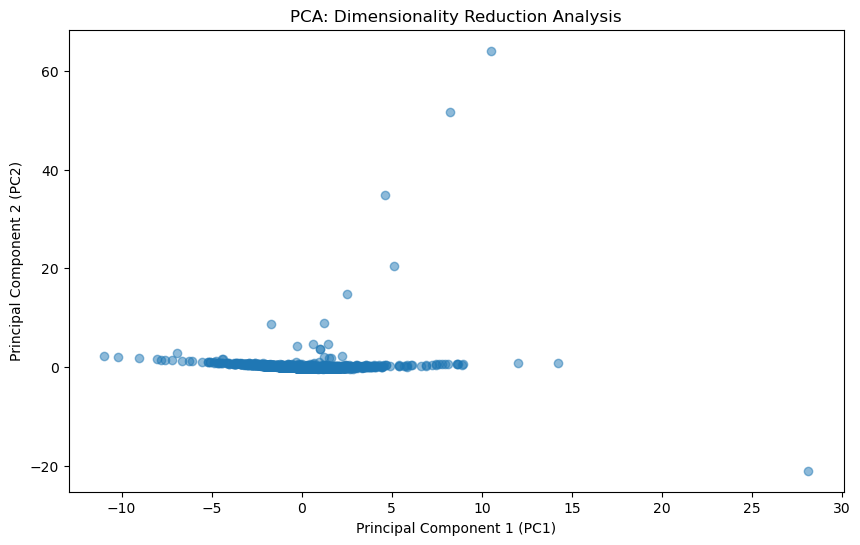

In [12]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def dimensionality_reduction_analysis(data, features_columns):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')
    data[features_columns] = imputer.fit_transform(data[features_columns])

    # Standardize the features
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(data[features_columns])

    # Apply PCA
    pca = PCA(n_components=2)  # You can adjust the number of components
    principal_components = pca.fit_transform(scaled_features)

    # Create a DataFrame with principal components
    pc_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])

    # Plot the results
    plt.figure(figsize=(10, 6))
    plt.scatter(pc_df['PC1'], pc_df['PC2'], alpha=0.5)
    plt.title('PCA: Dimensionality Reduction Analysis')
    plt.xlabel('Principal Component 1 (PC1)')
    plt.ylabel('Principal Component 2 (PC2)')
    plt.show()

# Example usage for dimensionality reduction analysis
features_columns_dimensionality_reduction = ['koi_period', 'koi_duration', 'koi_prad', 'koi_teq']  # Replace with relevant features
dimensionality_reduction_analysis(df, features_columns_dimensionality_reduction)


In [13]:
def stellar_parameters_analysis(data, target_column, stellar_params_columns):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')
    data[stellar_params_columns] = imputer.fit_transform(data[stellar_params_columns])

    # Split the data into features (X) and target variable (y)
    X = data[stellar_params_columns]
    y = data[target_column]

    # Split the data into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # Initialize a RandomForestClassifier (you can choose a different classifier)
    clf = RandomForestClassifier(n_estimators=100, random_state=42)

    # Train the model
    clf.fit(X_train, y_train)

    # Make predictions
    y_pred = clf.predict(X_test)

    # Evaluate the model
    accuracy = accuracy_score(y_test, y_pred)
    confusion_mat = confusion_matrix(y_test, y_pred)
    classification_rep = classification_report(y_test, y_pred)

    print(f'Accuracy: {accuracy:.2f}')
    print('\nConfusion Matrix:')
    print(confusion_mat)
    print('\nClassification Report:')
    print(classification_rep)

# Example usage for stellar parameters analysis
target_column_stellar = 'koi_disposition'
stellar_params_columns = ['koi_steff', 'koi_slogg', 'koi_srad']  # Replace with relevant stellar parameters
stellar_parameters_analysis(df, target_column_stellar, stellar_params_columns)


Accuracy: 0.60

Confusion Matrix:
[[100  99 252]
 [ 79 248 127]
 [113  91 804]]

Classification Report:
                precision    recall  f1-score   support

     CANDIDATE       0.34      0.22      0.27       451
     CONFIRMED       0.57      0.55      0.56       454
FALSE POSITIVE       0.68      0.80      0.73      1008

      accuracy                           0.60      1913
     macro avg       0.53      0.52      0.52      1913
  weighted avg       0.57      0.60      0.58      1913



Silhouette Score: 0.79
An error occurred during clustering: np.False_


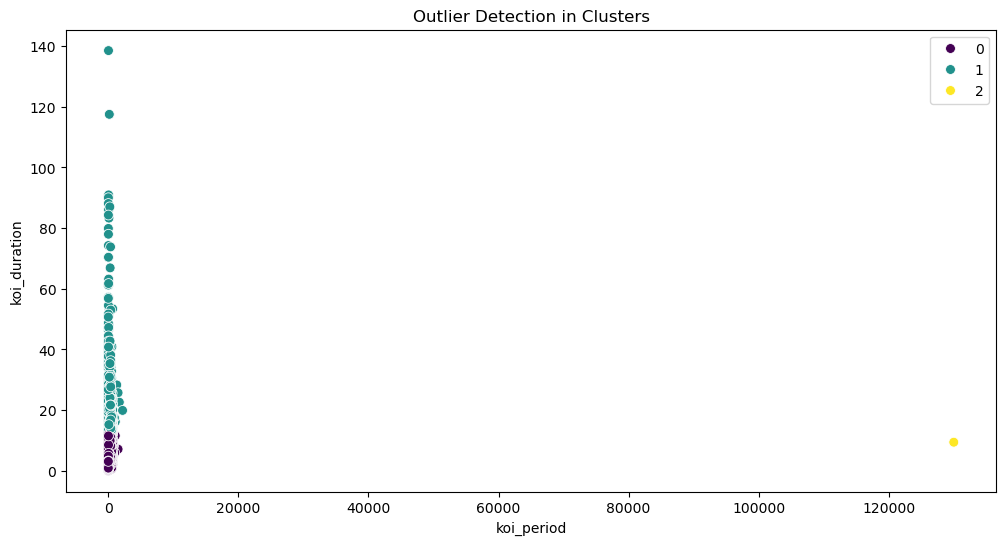

In [14]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

def outlier_detection_in_clusters(data, features_columns, num_clusters):
    # Handling missing values
    imputer = SimpleImputer(strategy='mean')
    data[features_columns] = imputer.fit_transform(data[features_columns])

    # Standardize the features
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(data[features_columns])

    # Apply KMeans clustering
    kmeans = KMeans(n_clusters=num_clusters, random_state=42)

    try:
        data['cluster_label'] = kmeans.fit_predict(scaled_features)
        silhouette_avg = silhouette_score(scaled_features, data['cluster_label'])
        print(f'Silhouette Score: {silhouette_avg:.2f}')

        # Identify outliers based on silhouette score
        if silhouette_avg is not None:
            outliers = data[silhouette_score(scaled_features, data['cluster_label']) < 0]
        else:
            outliers = pd.DataFrame()
    except Exception as e:
        print(f"An error occurred during clustering: {e}")
        outliers = pd.DataFrame()

    # Visualize the clusters and outliers
    plt.figure(figsize=(12, 6))
    sns.scatterplot(x=features_columns[0], y=features_columns[1], hue='cluster_label', data=data, palette='viridis', s=50)
    if not outliers.empty:
        sns.scatterplot(x=features_columns[0], y=features_columns[1], data=outliers, color='red', s=100, marker='x', label='Outliers')
    plt.title('Outlier Detection in Clusters')
    plt.xlabel(features_columns[0])
    plt.ylabel(features_columns[1])
    plt.legend()
    plt.show()

# Example usage for outlier detection in clusters
features_columns_outlier_detection = ['koi_period', 'koi_duration']
num_clusters_outlier_detection = 3  # You can adjust the number of clusters
outlier_detection_in_clusters(df, features_columns_outlier_detection, num_clusters_outlier_detection)


---
# 2 TRAITEMENT DISTRIBUÉ - PySpark

**Objectif de l'étape** : refaire le chargement, le nettoyage, l'agrégation et un modèle de classification avec **Apache Spark** (PySpark), pour que le même code puisse passer à l'échelle sur un cluster **Hadoop** (stockage HDFS + gestionnaire de ressources YARN).

> Remarque honnête : `cumulative.csv` ne pèse que quelques Mo, Spark n'est donc pas nécessaire pour ce volume. L'intérêt ici est d'obtenir un pipeline identique en local et sur un cluster (changer seulement la ligne `master` et les chemins).

**Plan** : 2.1 Session et chargement → 2.2 Audit qualité → 2.3 Nettoyage → 2.4 Agrégations (DataFrame + SQL) → 2.5 Features + modèle → 2.6 Évaluation → 2.7 Scoring des candidats → 2.8 Sauvegarde → 2.9 Exécution sur Hadoop


In [16]:
%pip install "pyspark==3.5.3"

     ---------------------------------------- 0.0/317.3 MB ? eta -:--:--
     --------------------------------------- 2.4/317.3 MB 17.8 MB/s eta 0:00:18
     - ------------------------------------- 8.4/317.3 MB 24.2 MB/s eta 0:00:13
     - ------------------------------------ 14.2/317.3 MB 26.4 MB/s eta 0:00:12
     -- ----------------------------------- 18.6/317.3 MB 25.1 MB/s eta 0:00:12
     -- ----------------------------------- 23.3/317.3 MB 24.0 MB/s eta 0:00:13
     --- ---------------------------------- 28.8/317.3 MB 24.4 MB/s eta 0:00:12
     ---- --------------------------------- 33.8/317.3 MB 24.5 MB/s eta 0:00:12
     ---- --------------------------------- 38.5/317.3 MB 24.3 MB/s eta 0:00:12
     ----- -------------------------------- 43.3/317.3 MB 24.0 MB/s eta 0:00:12
     ----- -------------------------------- 48.2/317.3 MB 23.9 MB/s eta 0:00:12
     ------ ------------------------------- 53.7/317.3 MB 24.0 MB/s eta 0:00:11
     ------- ------------------------------ 59.

  DEPRECATION: Building 'pyspark' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'pyspark'. Discussion can be found at https://github.com/pypa/pip/issues/6334


## 2.1 Session Spark et chargement des données

In [1]:
# !pip install pyspark   # (Java 8/11/17 requis)
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.types import DoubleType

spark = (SparkSession.builder
         .appName("kepler-koi-pyspark")
         .master("local[*]")                      # sur Hadoop : .master("yarn")
         .config("spark.sql.shuffle.partitions", "8")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")

# Local : "cumulative.csv" | HDFS : "hdfs:///data/kepler/cumulative.csv"
CSV_PATH = "cumulative.csv"

sdf = (spark.read
       .option("header", True)
       .option("inferSchema", True)
       .csv(CSV_PATH))

print("Lignes :", sdf.count(), "| Colonnes :", len(sdf.columns))
sdf.printSchema()
sdf.show(5, truncate=False)


PySparkRuntimeError: [JAVA_GATEWAY_EXITED] Java gateway process exited before sending its port number.

## 2.2 Audit de la qualité : valeurs manquantes par colonne

In [ ]:
n_rows = sdf.count()

# Les colonnes texte ne peuvent pas être testées avec isnan : on sépare les types
num_cols = [f.name for f in sdf.schema.fields if f.dataType.typeName() in ("double", "float", "integer", "long")]
all_cols = sdf.columns

missing = sdf.select([
    (F.count(F.when(F.col(c).isNull() | F.isnan(c), c)) if c in num_cols
     else F.count(F.when(F.col(c).isNull(), c))).alias(c)
    for c in all_cols
])

# Passage en format long : une ligne par colonne
pairs = F.explode(F.array(*[F.struct(F.lit(c).alias("colonne"), F.col(c).cast("long").alias("manquants")) for c in all_cols]))
missing_long = (missing.select(pairs.alias("kv")).select("kv.colonne", "kv.manquants")
                .withColumn("pct", F.round(F.col("manquants") / n_rows * 100, 1))
                .orderBy(F.desc("manquants")))
missing_long.show(20, truncate=False)


## 2.3 Nettoyage et préparation

- suppression des colonnes entièrement vides (`koi_teq_err1/err2`) et des identifiants non informatifs ;
- suppression des doublons ;
- **on garde seulement CONFIRMED et FALSE POSITIVE pour l'entraînement** (les CANDIDATE n'ont pas de vérité terrain : on les scorera ensuite) ;
- les colonnes `koi_score`, `koi_pdisposition` et `koi_fpflag_*` sont **exclues des features** (fuite de données, voir le dictionnaire).

In [ ]:
# 1) colonnes 100 % vides
empty_cols = [r["colonne"] for r in missing_long.filter(F.col("manquants") == n_rows).collect()]
print("Colonnes vides supprimées :", empty_cols)

# 2) colonnes d'identification / fuite
id_cols      = ["rowid", "kepoi_name", "kepler_name", "koi_tce_delivname"]
leakage_cols = ["koi_score", "koi_pdisposition", "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]

clean = sdf.drop(*empty_cols).dropDuplicates()

# 3) transformations log pour les variables très asymétriques (log1p évite log(0))
for c in ["koi_period", "koi_depth", "koi_prad", "koi_insol", "koi_model_snr"]:
    clean = clean.withColumn(f"log_{c}", F.log1p(F.col(c)))

clean.cache()
print("Lignes après nettoyage :", clean.count())


## 2.4 Agrégations distribuées (API DataFrame puis Spark SQL)

In [ ]:
# Répartition des verdicts
clean.groupBy("koi_disposition").count().orderBy(F.desc("count")).show()

# Statistiques physiques par verdict (médiane approchée = percentile_approx)
(clean.groupBy("koi_disposition")
      .agg(F.count("*").alias("n"),
           F.round(F.expr("percentile_approx(koi_period, 0.5)"), 2).alias("periode_mediane_j"),
           F.round(F.expr("percentile_approx(koi_prad, 0.5)"), 2).alias("rayon_median_Rterre"),
           F.round(F.avg("koi_model_snr"), 1).alias("snr_moyen"))
      .orderBy("koi_disposition")
      .show())

# Étoiles avec le plus de candidats (systèmes multi-planétaires)
(clean.groupBy("kepid").agg(F.count("*").alias("nb_koi"))
      .orderBy(F.desc("nb_koi")).show(10))

# Même chose en SQL
clean.createOrReplaceTempView("koi")
spark.sql("""
    SELECT koi_disposition,
           COUNT(*)                          AS n,
           ROUND(AVG(koi_teq), 0)            AS teq_moyenne_K,
           ROUND(AVG(koi_steff), 0)          AS steff_moyenne_K
    FROM koi
    GROUP BY koi_disposition
    ORDER BY n DESC
""").show()

# Planètes confirmées de taille terrestre/super-terrestre en zone d'insolation proche de la Terre
spark.sql("""
    SELECT kepoi_name, kepler_name, koi_prad, koi_insol, koi_teq
    FROM koi
    WHERE koi_disposition = 'CONFIRMED'
      AND koi_prad BETWEEN 0.8 AND 2.0
      AND koi_insol BETWEEN 0.25 AND 2.0
    ORDER BY koi_insol
""").show(20, truncate=False)


## 2.5 Features et modèle (Spark ML)

- **Cible binaire** : `1` = CONFIRMED, `0` = FALSE POSITIVE.
- **Découpage par étoile** (`kepid`) et non par ligne : plusieurs KOI d'une même étoile ne se retrouvent pas à la fois en train et en test.
- **Imputation par la médiane** à l'intérieur du `Pipeline`, donc apprise sur le train uniquement (le notebook initial impute sur tout le jeu avant le split).
- **Poids de classe** pour compenser le déséquilibre.

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.functions import vector_to_array

feature_cols = [
    "log_koi_period", "koi_duration", "log_koi_depth", "log_koi_prad", "koi_impact",
    "koi_teq", "log_koi_insol", "log_koi_model_snr",
    "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag",
]

labeled = (clean.filter(F.col("koi_disposition").isin("CONFIRMED", "FALSE POSITIVE"))
                .withColumn("label", F.when(F.col("koi_disposition") == "CONFIRMED", 1.0).otherwise(0.0)))

# Poids de classe : la classe minoritaire (CONFIRMED) pèse plus
n_pos = labeled.filter("label = 1").count()
n_neg = labeled.filter("label = 0").count()
labeled = labeled.withColumn("w", F.when(F.col("label") == 1.0, n_neg / n_pos).otherwise(1.0))

# Découpage 80/20 déterministe par étoile
labeled = labeled.withColumn("bucket", F.pmod(F.hash("kepid"), F.lit(10)))
train = labeled.filter("bucket < 8")
test  = labeled.filter("bucket >= 8")
print(f"train = {train.count()} | test = {test.count()}")

# Spark ML veut des doubles
for c in feature_cols:
    train = train.withColumn(c, F.col(c).cast(DoubleType()))
    test  = test.withColumn(c, F.col(c).cast(DoubleType()))

imputer   = Imputer(strategy="median", inputCols=feature_cols, outputCols=[f"{c}_imp" for c in feature_cols])
assembler = VectorAssembler(inputCols=[f"{c}_imp" for c in feature_cols], outputCol="features")
rf        = RandomForestClassifier(labelCol="label", featuresCol="features", weightCol="w", seed=42)

pipeline = Pipeline(stages=[imputer, assembler, rf])

grid = (ParamGridBuilder()
        .addGrid(rf.numTrees, [50, 100])
        .addGrid(rf.maxDepth, [6, 10])
        .build())

cv = CrossValidator(estimator=pipeline, estimatorParamMaps=grid,
                    evaluator=BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC"),
                    numFolds=3, seed=42, parallelism=2)

cv_model = cv.fit(train)
best = cv_model.bestModel
print("AUC moyen en validation croisée par combinaison :", [round(m, 4) for m in cv_model.avgMetrics])


## 2.6 Évaluation sur le jeu de test

In [ ]:
pred = best.transform(test)

auc = BinaryClassificationEvaluator(labelCol="label", metricName="areaUnderROC").evaluate(pred)
acc = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy").evaluate(pred)
f1  = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1").evaluate(pred)
print(f"AUC = {auc:.3f} | Accuracy = {acc:.3f} | F1 = {f1:.3f}")

print("Matrice de confusion (lignes = réalité, colonnes = prédiction) :")
pred.groupBy("label").pivot("prediction", [0.0, 1.0]).count().orderBy("label").show()

# Importance des variables
rf_model = best.stages[-1]
importances = sorted(zip(feature_cols, rf_model.featureImportances.toArray()), key=lambda t: -t[1])
for name, imp in importances:
    print(f"{name:<20s} {imp:.3f}")


## 2.7 Scoring des candidats (`CANDIDATE`)

Les 2 248 candidats n'ont pas encore de verdict : on les classe par probabilité d'être une vraie planète. C'est un **outil de priorisation**, pas une confirmation.

In [ ]:
candidates = clean.filter(F.col("koi_disposition") == "CANDIDATE")
for c in feature_cols:
    candidates = candidates.withColumn(c, F.col(c).cast(DoubleType()))

scored = (best.transform(candidates)
          .withColumn("proba_planete", F.round(vector_to_array("probability")[1], 3))
          .select("kepoi_name", "kepid", "koi_period", "koi_prad", "koi_teq", "proba_planete")
          .orderBy(F.desc("proba_planete")))

scored.show(20, truncate=False)


## 2.8 Sauvegarde (Parquet, format colonnaire adapté à HDFS)

In [ ]:
OUT = "output"          # sur HDFS : "hdfs:///data/kepler/output"

clean.write.mode("overwrite").parquet(f"{OUT}/kepler_clean.parquet")
scored.write.mode("overwrite").parquet(f"{OUT}/candidates_scored.parquet")
best.write().overwrite().save(f"{OUT}/rf_pipeline_model")

# Relecture rapide pour vérifier
spark.read.parquet(f"{OUT}/kepler_clean.parquet").groupBy("koi_disposition").count().show()

# spark.stop()   # à lancer en fin de session


## 2.9 Exécuter sur un cluster Hadoop

Le code ne change presque pas. Trois ajustements :

1. **Mettre les données dans HDFS** :
   ```bash
   hdfs dfs -mkdir -p /data/kepler
   hdfs dfs -put cumulative.csv /data/kepler/
   ```
2. **Adapter le code** : `CSV_PATH = "hdfs:///data/kepler/cumulative.csv"`, `OUT = "hdfs:///data/kepler/output"`, et retirer `.master("local[*]")` (ou mettre `"yarn"`).
3. **Soumettre le script** (notebook exporté en `.py`) à YARN :
   ```bash
   spark-submit --master yarn --deploy-mode cluster \
     --num-executors 4 --executor-memory 2g --executor-cores 2 \
     kepler_pyspark.py
   ```

**Spark ou MapReduce ?** Spark remplace avantageusement MapReduce pour ce type de traitement (calcul en mémoire, API DataFrame, Spark ML), tout en s'appuyant sur HDFS et YARN de Hadoop.
